In [1]:
# %pip install -q ftfy regex tqdm scikit-image git+https://github.com/openai/CLIP.git
# %pip install scikit-learn

In [2]:
import clip
from collections import Counter, defaultdict
import json
import matplotlib.pyplot as plt
import numpy as np
from pathlib import Path
from PIL import Image, ImageOps
from sklearn.cluster import KMeans
import time
import torch
 
device = "cuda" if torch.cuda.is_available() else "cpu"
print("Using:", device)

Using: cpu


In [3]:
PHOTO_DIR = Path("photos")

# load metadata
with open("photos.json") as f:
    photos = json.load(f)
json_names = list(photos.keys())

# names of image files actually in folder (ignores .DS_Store, etc.)
image_suffixes = {".jpeg", ".jpg", ".png"}
folder_names = [
    item.name for item in PHOTO_DIR.iterdir()
    if item.suffix.lower() in image_suffixes
]

# cross-check JSON against folder, in both directions 
for name in json_names:
    if name not in folder_names:
        print("In JSON but not in folder:", name)
for name in folder_names:
    if name not in json_names:
        print("In folder but not in JSON:", name)

# canonical order: row i of every later array refers to filenames[i]
filenames = sorted(photos)
image_paths = [PHOTO_DIR / name for name in filenames]
print("Number of images: ", len(image_paths))

# ensures that grid, inspection, and batching steps load the same way
def load_image(path):
    # open photo, apply iPhone rotation tag, convert to RGB
    return ImageOps.exif_transpose(Image.open(path)).convert("RGB")

Number of images:  30


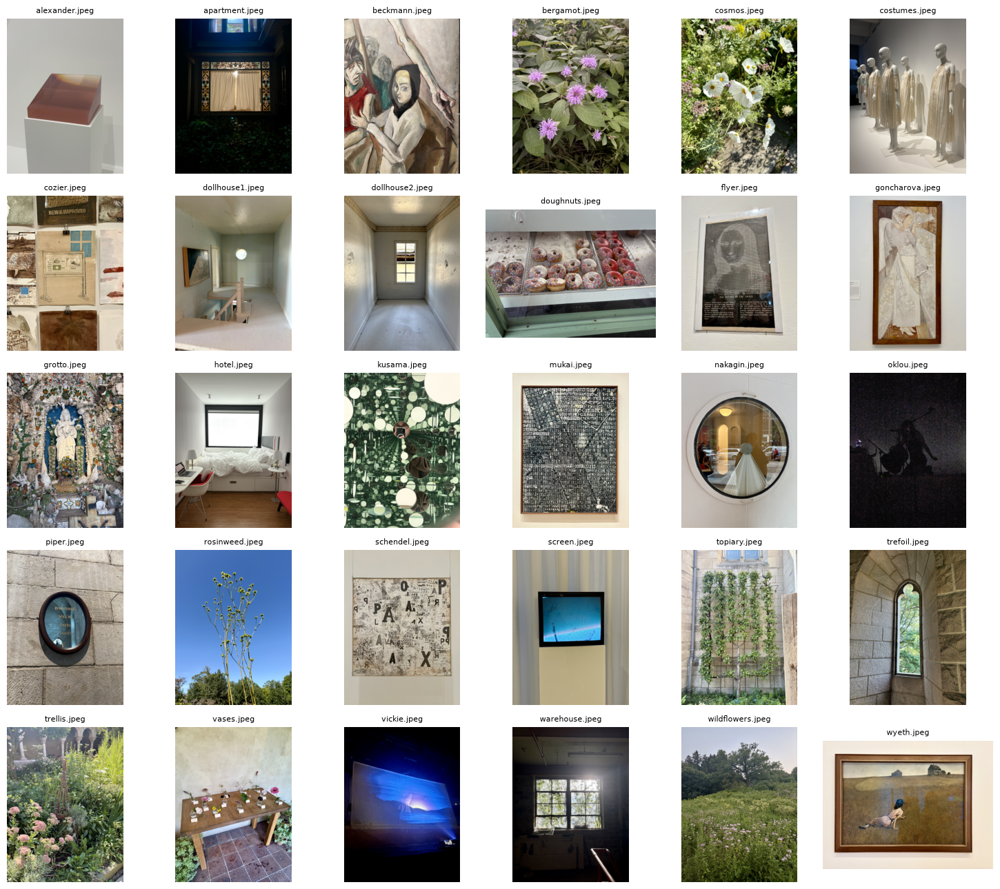

In [4]:
# create labeled thumbnail grid
fig, axes = plt.subplots(5, 6, figsize=(15, 13))
for ax, path in zip(axes.flat, image_paths):
    image = load_image(path)
    image.thumbnail((400, 400)) # shrinks in place
    ax.imshow(image)
    ax.set_title(path.name, fontsize=8)
    ax.axis("off")
plt.tight_layout()
fig.savefig("collection_grid.png", dpi=200, bbox_inches="tight")
plt.show()

In [5]:
# image count, groups/themes
all_tags = []
for filename, info in photos.items():
    for tag in info["tags"]:
        all_tags.append(tag)
print(len(all_tags))

tag_counts = Counter(all_tags)
print(tag_counts, sum(tag_counts.values()))

# tag -> list of filenames that carry it
members = defaultdict(list)
for filename, info in sorted(photos.items()):       # sorted = alphabetical, reproducible
    for tag in info["tags"]:
        members[tag].append(filename)

order = ["flower", "frame", "window", "woman", "art", "text", "multiple", "confuser"]

# checks
print("tags not in `order`:", set(members) - set(order))           # should print set()
print("total tag count:", sum(len(v) for v in members.values()))   # should match Counter total

main = {"flower", "frame", "window", "woman"}
in_main = [fn for fn, info in photos.items() if main & set(info["tags"])]
print("photos in at least one main group:", len(in_main))

# readable listing
for tag in order:
    print(f"\n{tag} ({len(members[tag])}): {', '.join(members[tag])}")

60
Counter({'art': 11, 'confuser': 11, 'multiple': 8, 'window': 7, 'woman': 7, 'flower': 6, 'text': 5, 'frame': 5}) 60
tags not in `order`: set()
total tag count: 60
photos in at least one main group: 23

flower (6): bergamot.jpeg, cosmos.jpeg, rosinweed.jpeg, trellis.jpeg, vases.jpeg, wildflowers.jpeg

frame (5): dollhouse1.jpeg, goncharova.jpeg, mukai.jpeg, piper.jpeg, wyeth.jpeg

window (7): apartment.jpeg, dollhouse2.jpeg, doughnuts.jpeg, hotel.jpeg, nakagin.jpeg, trefoil.jpeg, warehouse.jpeg

woman (7): beckmann.jpeg, flyer.jpeg, goncharova.jpeg, grotto.jpeg, oklou.jpeg, vickie.jpeg, wyeth.jpeg

art (11): alexander.jpeg, beckmann.jpeg, costumes.jpeg, cozier.jpeg, goncharova.jpeg, kusama.jpeg, mukai.jpeg, piper.jpeg, schendel.jpeg, screen.jpeg, wyeth.jpeg

text (5): cozier.jpeg, flyer.jpeg, mukai.jpeg, piper.jpeg, schendel.jpeg

multiple (8): bergamot.jpeg, cosmos.jpeg, costumes.jpeg, cozier.jpeg, rosinweed.jpeg, trellis.jpeg, vases.jpeg, wildflowers.jpeg

confuser (11): alexander.

In [6]:
# single image inspection
image = load_image(image_paths[0])
array = np.asarray(image)
print("PIL size (width, height):", image.size)
print("Array shape (H, W, C):   ", array.shape)
print("Array dtype:             ", array.dtype)
print("Array range:             ", array.min(), "to", array.max())

PIL size (width, height): (4284, 5712)
Array shape (H, W, C):    (5712, 4284, 3)
Array dtype:              uint8
Array range:              34 to 255


In [7]:
# load CLIP and use its preprocessing
model, preprocess = clip.load("ViT-B/32", device=device)
model.eval()
print(preprocess)

x0 = preprocess(image)
print("Preprocessed shape:", tuple(x0.shape))
print("Preprocessed dtype:", x0.dtype)
print("Preprocessed range:", float(x0.min()), "to", float(x0.max()))

/opt/anaconda3/envs/torch/lib/python3.12/site-packages/torch/jit/_serialization.py:176: FutureWarning: `torch.jit.load` is deprecated. Please switch to `torch.export`.
  warnings.warn(


Compose(
    Resize(size=224, interpolation=bicubic, max_size=None, antialias=True)
    CenterCrop(size=(224, 224))
    <function _convert_image_to_rgb at 0x13cf68a40>
    ToTensor()
    Normalize(mean=(0.48145466, 0.4578275, 0.40821073), std=(0.26862954, 0.26130258, 0.27577711))
)
Preprocessed shape: (3, 224, 224)
Preprocessed dtype: torch.float32
Preprocessed range: -0.9116621017456055 to 1.7903954982757568


In [8]:
# settings and embedding function
MODEL_NAME = "ViT-B/32"
CACHE_PATH = Path("clip_cache.pt")
BATCH_SIZE = 16

# return raw (unnormalized) CLIP embeddings, one row per path, in order
def embed_images(paths, batch_size=BATCH_SIZE):
    chunks = []
    for start in range(0, len(paths), batch_size):
        batch_paths = paths[start:start + batch_size]
        batch = torch.stack([preprocess(load_image(p)) for p in batch_paths]).to(device)
        with torch.inference_mode():
            chunks.append(model.encode_image(batch).float().cpu())
    return torch.cat(chunks)


In [9]:
# load from cache or compute if cache empty
image_embeddings = None

if CACHE_PATH.exists():
    cache = torch.load(CACHE_PATH)
    if cache["filenames"] == filenames and cache["model"] == MODEL_NAME:
        image_embeddings = cache["embeddings"]
        print("Loaded cached embeddings:", tuple(image_embeddings.shape))
    else:
        print("Cache is stale (different files or model); recomputing")

if image_embeddings is None:
    start = time.perf_counter()
    raw_embeddings = embed_images(image_paths)
    image_embeddings = raw_embeddings / raw_embeddings.norm(dim=1, keepdim=True)
    if device == "cuda":
        torch.cuda.synchronize()
    elapsed = time.perf_counter() - start

    # print raw norms, normalize, and print norms again
    print("Embedding matrix shape:", tuple(image_embeddings.shape))
    print("Embedding dtype:       ", image_embeddings.dtype)
    print("Raw norms (first 5):       ", raw_embeddings.norm(dim=1)[:5].numpy())
    print("Normalized norms (first 5):", image_embeddings.norm(dim=1)[:5].numpy())
    print(f"Time to embed collection:   {elapsed:.2f} s")

    torch.save(
        {"filenames": filenames, "embeddings": image_embeddings, "model": MODEL_NAME},
        CACHE_PATH,
    )
    print("Saved cache to", CACHE_PATH)

Embedding matrix shape: (30, 512)
Embedding dtype:        torch.float32
Raw norms (first 5):        [11.289368 10.960736 10.318168  9.96706  11.005809]
Normalized norms (first 5): [0.99999994 1.         1.         0.99999994 1.        ]
Time to embed collection:   4.65 s
Saved cache to clip_cache.pt


In [10]:
# cosine similarity between one text query and every image, in filenames order
def embed_text(query):
    """One text query -> normalized CLIP text embedding, shape (1, 512)."""
    tokens = clip.tokenize([query]).to(device)
    with torch.inference_mode():
        emb = model.encode_text(tokens).float().cpu()
    return emb / emb.norm(dim=1, keepdim=True)


def score_embedding(text_emb):
    """Cosine similarity of one normalized text embedding against every image, shape (30,)."""
    return (image_embeddings @ text_emb.T).squeeze(1)


def score_all(query):
    """Same behavior as my original score_all, now built from the two pieces above."""
    return score_embedding(embed_text(query))

# top-k (filename, score) pairs, best first
def search(query, k=3):
    scores = score_all(query)
    order = torch.argsort(scores, descending=True).tolist()
    return [(filenames[i], scores[i].item()) for i in order[:k]]

# 1-based rank of one specific image for a query (for failure analysis)
def rank_of(query, filename):
    order = torch.argsort(score_all(query), descending=True).tolist()
    return order.index(filenames.index(filename)) + 1

# compact retrieval figure: top-k images with rank, filename, and score
def show_results(query, k=3):
    results = search(query, k)
    fig, axes = plt.subplots(1, k, figsize=(4 * k, 5), squeeze=False)
    for ax, (name, score), rank in zip(axes[0], results, range(1, k + 1)):
        img = load_image(PHOTO_DIR / name)
        img.thumbnail((500, 500))
        ax.imshow(img)
        ax.set_title(f"#{rank}: {name}\n{score:.3f}", fontsize=12)
        ax.axis("off")
    fig.suptitle(f'Query: "{query}"')
    plt.tight_layout()
    plt.show()

['bergamot.jpeg', 'cosmos.jpeg', 'rosinweed.jpeg', 'trellis.jpeg', 'vases.jpeg', 'wildflowers.jpeg']


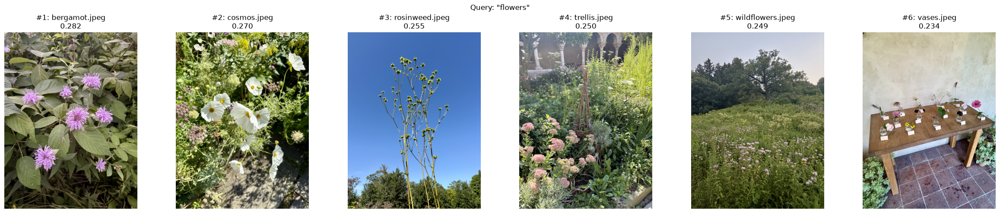

In [11]:
expected = {fn for fn, info in photos.items() if "flower" in info["tags"]}
print(sorted(expected))
show_results("flowers", k=6)

['bergamot.jpeg', 'cosmos.jpeg', 'rosinweed.jpeg', 'trellis.jpeg', 'vases.jpeg', 'wildflowers.jpeg']


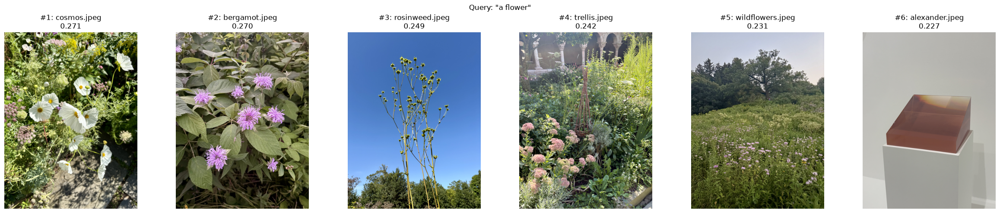

In [12]:
expected = {fn for fn, info in photos.items() if "flower" in info["tags"]}
print(sorted(expected))
show_results("a flower", k=6)

['apartment.jpeg', 'dollhouse2.jpeg', 'doughnuts.jpeg', 'hotel.jpeg', 'nakagin.jpeg', 'trefoil.jpeg', 'warehouse.jpeg']


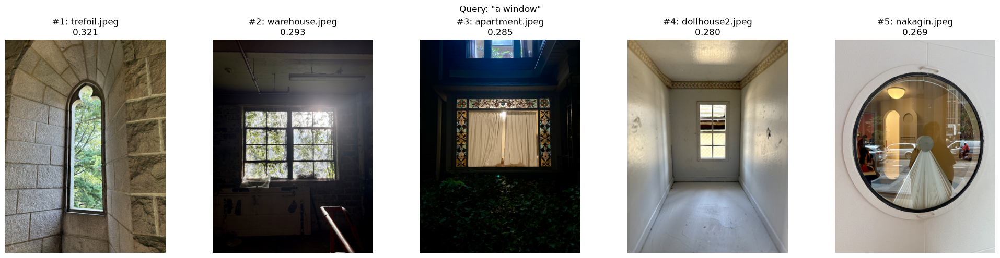

In [13]:
expected = {fn for fn, info in photos.items() if "window" in info["tags"]}
print(sorted(expected))
show_results("a window", k=5)

['dollhouse1.jpeg', 'goncharova.jpeg', 'mukai.jpeg', 'piper.jpeg', 'wyeth.jpeg']


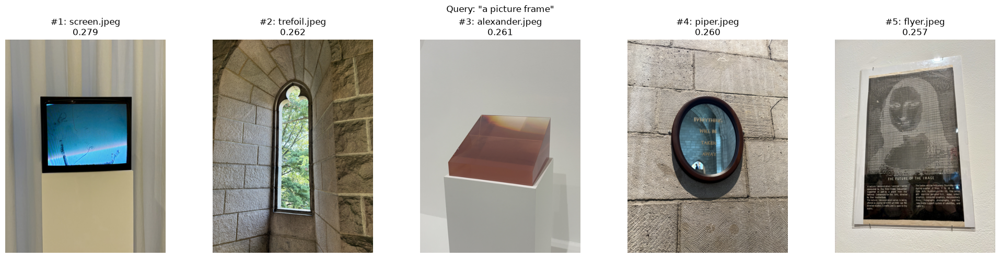

In [14]:
expected = {fn for fn, info in photos.items() if "frame" in info["tags"]}
print(sorted(expected))
show_results("a picture frame", k=5)

['alexander.jpeg', 'beckmann.jpeg', 'costumes.jpeg', 'cozier.jpeg', 'goncharova.jpeg', 'kusama.jpeg', 'mukai.jpeg', 'piper.jpeg', 'schendel.jpeg', 'screen.jpeg', 'wyeth.jpeg']


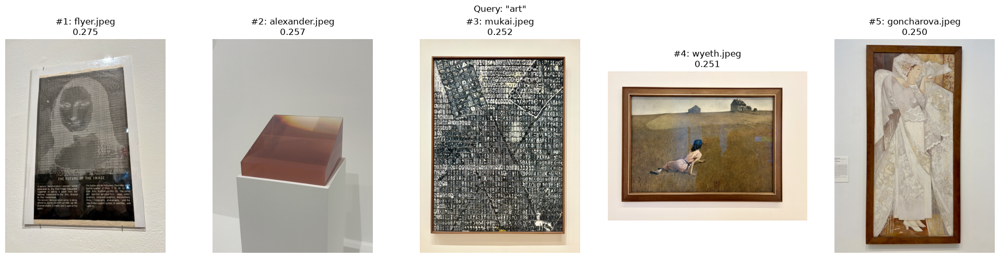

In [15]:
expected = {fn for fn, info in photos.items() if "art" in info["tags"]}
print(sorted(expected))
show_results("art", k=5)

['alexander.jpeg', 'beckmann.jpeg', 'costumes.jpeg', 'cozier.jpeg', 'goncharova.jpeg', 'kusama.jpeg', 'mukai.jpeg', 'piper.jpeg', 'schendel.jpeg', 'screen.jpeg', 'wyeth.jpeg']


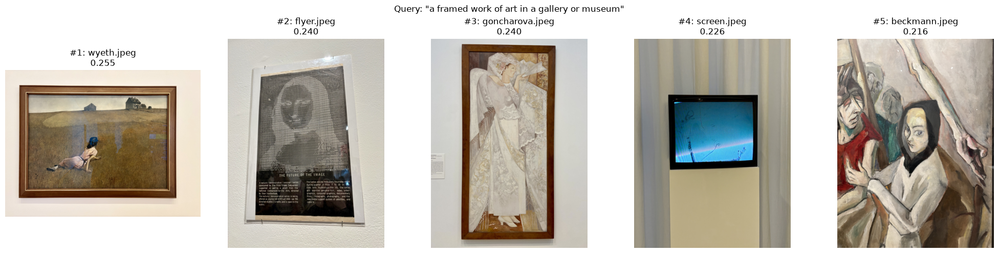

In [16]:
expected = {fn for fn, info in photos.items() if "art" in info["tags"]}
print(sorted(expected))
show_results("a framed work of art in a gallery or museum", k=5)

['cozier.jpeg', 'flyer.jpeg', 'mukai.jpeg', 'piper.jpeg', 'schendel.jpeg']


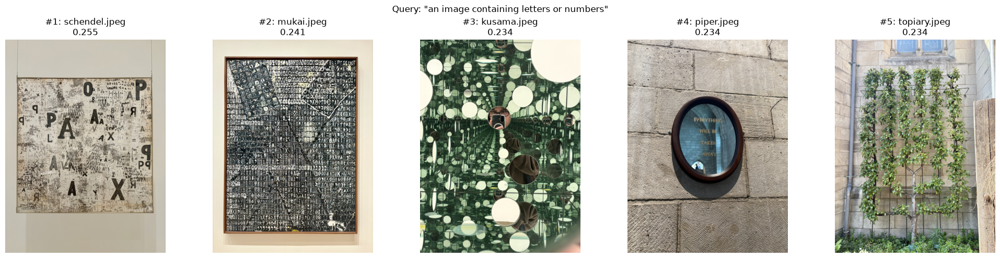

In [17]:
expected = {fn for fn, info in photos.items() if "text" in info["tags"]}
print(sorted(expected))
show_results("an image containing letters or numbers", k=5)

['beckmann.jpeg', 'flyer.jpeg', 'goncharova.jpeg', 'grotto.jpeg', 'oklou.jpeg', 'vickie.jpeg', 'wyeth.jpeg']


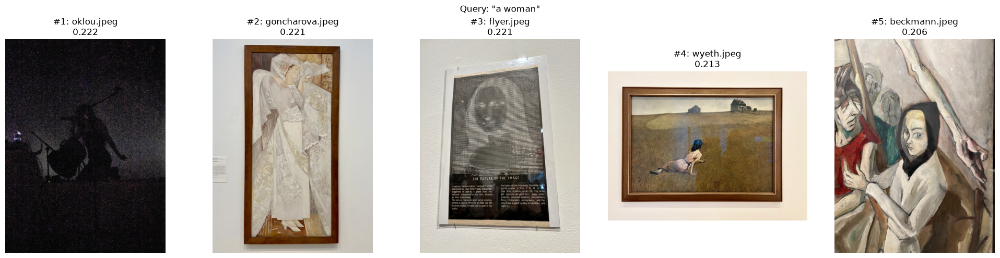

In [18]:
expected = {fn for fn, info in photos.items() if "woman" in info["tags"]}
print(sorted(expected))
show_results("a woman", k=5)

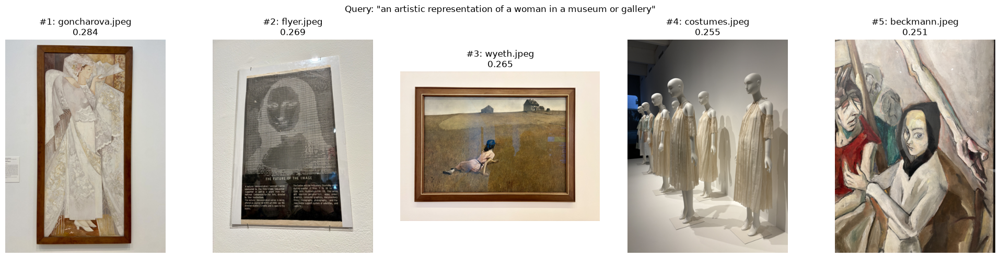

In [19]:
show_results("an artistic representation of a woman in a museum or gallery", k=5)

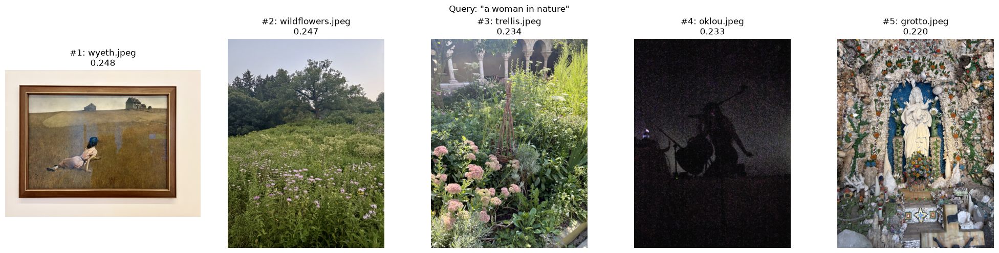

In [20]:
show_results("a woman in nature", k=5)

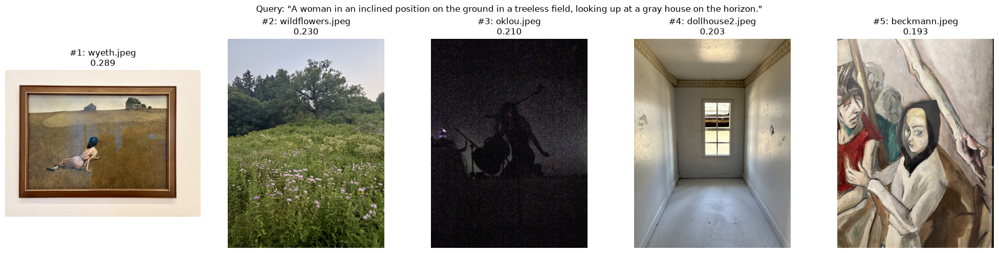

In [21]:
show_results("A woman in an inclined position on the ground in a treeless field, looking up at a gray house on the horizon.", k=5)

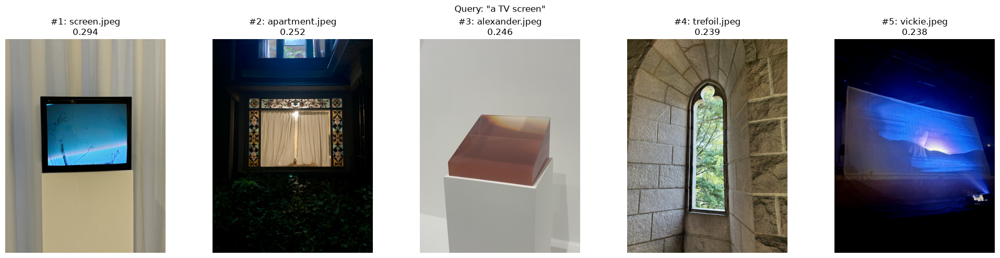

In [22]:
show_results("a TV screen", k=5)

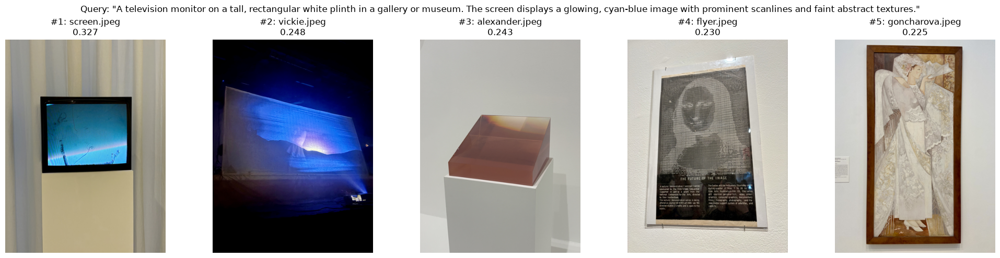

In [23]:
show_results("A television monitor on a tall, rectangular white plinth in a gallery or museum. The screen displays a glowing, cyan-blue image with prominent scanlines and faint abstract textures.", k=5)

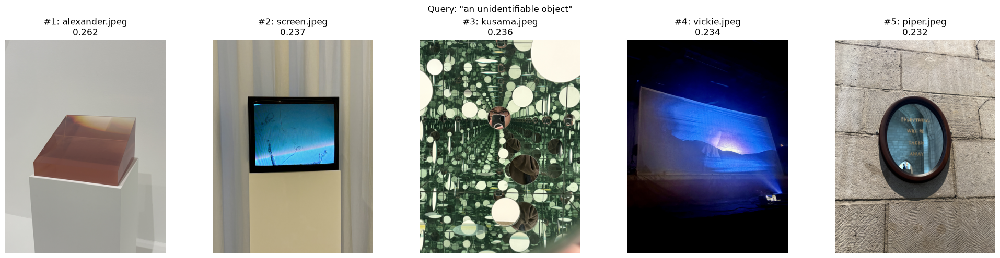

In [24]:
show_results("an unidentifiable object", k=5)

In [25]:
"""
Retrieval Margins: For at least five text queries, report both the highest and next highest similarity scores (and their difference). 
Compare a query with a clear winner against one with a more ambiguous ranking.
"""

# each query: predicted top photo or none
margin_queries = [
    ("a TV screen", "screen.jpeg"),
    ("A television monitor on a tall, rectangular white plinth in a gallery or museum. The screen displays a glowing, cyan-blue image with prominent scanlines and faint abstract textures.", "screen.jpeg"),
    ("a woman in nature", "wyeth.jpeg"),
    ("A woman in an inclined position on the ground in a treeless field, looking up at a gray house on the horizon.", "wyeth.jpeg"),
    ("a window", "apartment.jpeg"),
    ("a cat", None)
]

rows = []
for query, predicted in margin_queries:
    scores = score_all(query)
    values, indices = torch.topk(scores, 2)
    names = [filenames[i] for i in indices.tolist()]
    top, second = values.tolist()

    rows.append({
        "query": query,
        "top": names[0], "top_score": top,
        "second": names[1], "second_score": second,
        "margin": top - second,
        "predicted": predicted,
        "hit": None if predicted is None else (names[0] == predicted),
        "pred_rank": None if predicted is None else rank_of(query, predicted),
    })

for r in rows:
    print(f'{r["query"][:40]:40}  {r["top"]:<15} {r["top_score"]:.4f}  '
          f'{r["second"]:<15} {r["second_score"]:.4f}  margin {r["margin"]:.4f}  '
          f'hit={r["hit"]}  pred_rank={r["pred_rank"]}')

# sanity check: should match the first row
print(search(margin_queries[0][0], k=1), rows[0]["top"], rows[0]["top_score"])

a TV screen                               screen.jpeg     0.2943  apartment.jpeg  0.2520  margin 0.0422  hit=True  pred_rank=1
A television monitor on a tall, rectangu  screen.jpeg     0.3268  vickie.jpeg     0.2484  margin 0.0784  hit=True  pred_rank=1
a woman in nature                         wyeth.jpeg      0.2477  wildflowers.jpeg 0.2474  margin 0.0003  hit=True  pred_rank=1
A woman in an inclined position on the g  wyeth.jpeg      0.2895  wildflowers.jpeg 0.2304  margin 0.0591  hit=True  pred_rank=1
a window                                  trefoil.jpeg    0.3206  warehouse.jpeg  0.2930  margin 0.0276  hit=False  pred_rank=3
a cat                                     flyer.jpeg      0.2266  oklou.jpeg      0.2175  margin 0.0092  hit=None  pred_rank=None
[('screen.jpeg', 0.29425135254859924)] screen.jpeg 0.29425135254859924



Cluster 0  (3 photos)
  photos: ['cozier.jpeg', 'mukai.jpeg', 'schendel.jpeg']
  tags:   {'art': 3, 'text': 3, 'multiple': 1, 'frame': 1}

Cluster 1  (11 photos)
  photos: ['apartment.jpeg', 'dollhouse1.jpeg', 'dollhouse2.jpeg', 'doughnuts.jpeg', 'grotto.jpeg', 'hotel.jpeg', 'nakagin.jpeg', 'piper.jpeg', 'topiary.jpeg', 'trefoil.jpeg', 'warehouse.jpeg']
  tags:   {'window': 7, 'confuser': 4, 'frame': 2, 'woman': 1, 'art': 1, 'text': 1}

Cluster 2  (6 photos)
  photos: ['bergamot.jpeg', 'cosmos.jpeg', 'rosinweed.jpeg', 'trellis.jpeg', 'vases.jpeg', 'wildflowers.jpeg']
  tags:   {'flower': 6, 'multiple': 6}

Cluster 3  (5 photos)
  photos: ['alexander.jpeg', 'kusama.jpeg', 'oklou.jpeg', 'screen.jpeg', 'vickie.jpeg']
  tags:   {'confuser': 5, 'art': 3, 'woman': 2}

Cluster 4  (5 photos)
  photos: ['beckmann.jpeg', 'costumes.jpeg', 'flyer.jpeg', 'goncharova.jpeg', 'wyeth.jpeg']
  tags:   {'art': 4, 'woman': 4, 'confuser': 2, 'frame': 2, 'multiple': 1, 'text': 1}


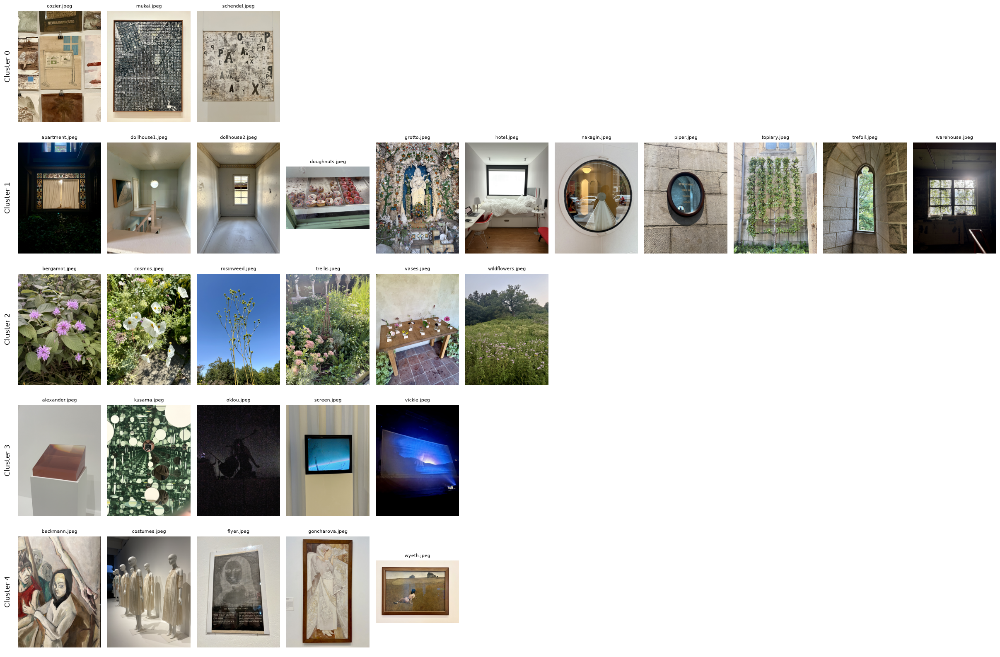

In [26]:
"""
Clustering Visualization: Cluster the CLIP image embeddings using k-means. 
Show the images assigned to every cluster, identify one coherent cluster and one less coherent cluster. 
Discuss how these clusters compare to the thematic groups you intended when capturing the original collection of images.
"""

K = 5
SEED = 0

emb = image_embeddings.numpy()                        # (30, 512)
km = KMeans(n_clusters=K, n_init=10, random_state=SEED).fit(emb)
labels = km.labels_                                   # cluster id per photo, in filenames order

# 1. membership and tag makeup of each cluster
clusters = {}
for c in range(K):
    members = [filenames[i] for i in range(len(filenames)) if labels[i] == c]
    clusters[c] = members
    tag_makeup = Counter(t for fn in members for t in photos[fn]["tags"])
    print(f"\nCluster {c}  ({len(members)} photos)")
    print("  photos:", members)
    print("  tags:  ", dict(tag_makeup.most_common()))

# 2. figure: one row per cluster
max_size = max(len(m) for m in clusters.values())
fig, axes = plt.subplots(K, max_size, figsize=(2.2 * max_size, 3.2 * K), squeeze=False)
for c in range(K):
    for j in range(max_size):
        ax = axes[c, j]
        ax.axis("off")
        if j < len(clusters[c]):
            img = load_image(PHOTO_DIR / clusters[c][j])
            img.thumbnail((300, 300))
            ax.imshow(img)
            ax.set_title(clusters[c][j], fontsize=8)
    axes[c, 0].text(-0.08, 0.5, f"Cluster {c}", transform=axes[c, 0].transAxes,
                    rotation=90, va="center", ha="right", fontsize=12)
plt.tight_layout()
fig.savefig("fig_clusters.png", dpi=200, bbox_inches="tight")
plt.show()

diagonal (should be ~1): [0.9999998211860657, 1.0, 1.0000001192092896]
number of pairs: 435
dollhouse1.jpeg  dollhouse2.jpeg  0.8945  shared tags: []
cosmos.jpeg      trellis.jpeg     0.8219  shared tags: ['flower', 'multiple']
mukai.jpeg       schendel.jpeg    0.8089  shared tags: ['art', 'text']
cozier.jpeg      kusama.jpeg      0.7939  shared tags: ['art']
alexander.jpeg   screen.jpeg      0.7913  shared tags: ['art', 'confuser']


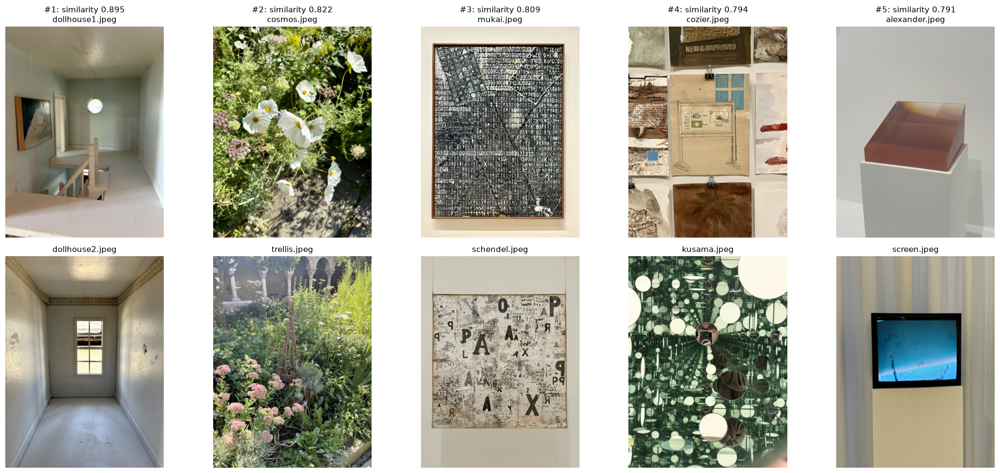

In [27]:
"""
Nearest-Pair Comparison: Find the five most similar pairs of images in your collection according to the embedding vectors. 
Display the pairs and discuss which visual or semantic properties appear to drive their similarity.
"""

n = len(filenames)

sim = image_embeddings @ image_embeddings.T     # (30, 30) cosine similarities
print("diagonal (should be ~1):", sim.diagonal()[:3].tolist())

# indices of the upper triangle: every pair once, no self-pairs
rows, cols = torch.triu_indices(n, n, offset=1)
pair_scores = sim[rows, cols]                    # one score per unique pair
print("number of pairs:", len(pair_scores))     # should be 435 = 30*29/2

top_vals, top_idx = torch.topk(pair_scores, 5)

top_pairs = []
for v, p in zip(top_vals.tolist(), top_idx.tolist()):
    a = filenames[rows[p].item()]
    b = filenames[cols[p].item()]
    top_pairs.append((a, b, v))
    shared = set(photos[a]["tags"]) & set(photos[b]["tags"])
    print(f"{a:<16} {b:<16} {v:.4f}  shared tags: {sorted(shared)}")

# figure: one column per pair, the two photos stacked
fig, axes = plt.subplots(2, 5, figsize=(20, 9))
for col, (a, b, score) in enumerate(top_pairs):
    for row, name in enumerate((a, b)):
        img = load_image(PHOTO_DIR / name)
        img.thumbnail((500, 500))
        axes[row, col].imshow(img)
        axes[row, col].axis("off")
    axes[0, col].set_title(f"#{col + 1}: similarity {score:.3f}\n{a}", fontsize=11)
    axes[1, col].set_title(b, fontsize=11)
plt.tight_layout()
fig.savefig("fig_nearest_pairs.png", dpi=200, bbox_inches="tight")
plt.show()


In [28]:
"""
Prompt Templates: For at least two fixed queries, compare the raw query with at least three template variations, 
such as “a photo of [query],” “an image containing [query],” and “a close-up photo of [query].” 
Show where the rankings change and identify the most consequential change.
"""

template_queries = ["a window", "a woman in nature"]      
targets = {                                                
    "a window": "apartment.jpeg",
    "a woman in nature": "wyeth.jpeg",               
}
templates = [
    "{}",                      
    "a photo of {}",
    "an image containing {}",
    "a close-up photo of {}",
]

TOP_N = 5
for q in template_queries:
    print(f'\nQuery: "{q}"   (target: {targets[q]})')
    for t in templates:
        text = t.format(q)
        scores = score_all(text)
        order = torch.argsort(scores, descending=True).tolist()

        top_scores = [scores[i].item() for i in order[:2]]
        margin = top_scores[0] - top_scores[1]
        target_rank = order.index(filenames.index(targets[q])) + 1

        top = ", ".join(f"{filenames[i]} ({scores[i].item():.3f})" for i in order[:TOP_N])
        print(f"  {text:<38} target rank {target_rank:<2} margin {margin:.4f}")
        print(f"      top {TOP_N}: {top}")


Query: "a window"   (target: apartment.jpeg)
  a window                               target rank 3  margin 0.0276
      top 5: trefoil.jpeg (0.321), warehouse.jpeg (0.293), apartment.jpeg (0.285), dollhouse2.jpeg (0.280), nakagin.jpeg (0.269)
  a photo of a window                    target rank 4  margin 0.0128
      top 5: trefoil.jpeg (0.325), warehouse.jpeg (0.312), dollhouse2.jpeg (0.296), apartment.jpeg (0.294), nakagin.jpeg (0.285)
  an image containing a window           target rank 5  margin 0.0253
      top 5: trefoil.jpeg (0.332), warehouse.jpeg (0.307), nakagin.jpeg (0.294), dollhouse2.jpeg (0.292), apartment.jpeg (0.285)
  a close-up photo of a window           target rank 5  margin 0.0462
      top 5: trefoil.jpeg (0.336), warehouse.jpeg (0.290), nakagin.jpeg (0.280), piper.jpeg (0.279), apartment.jpeg (0.277)

Query: "a woman in nature"   (target: wyeth.jpeg)
  a woman in nature                      target rank 1  margin 0.0003
      top 5: wyeth.jpeg (0.248), wildflowe

In [29]:
"""
Query Expansion and Prompt Ensembling: For a single user query, generate several related prompts 
(e.g., "a photo of [query]", "a rendering of [query]", etc.) and combine their embeddings. 
"""

# ensemble and scoring helper 
ensemble_templates = [
    "{}",
    "a photo of {}",
    "a close-up photo of {}",
    "an image containing {}",
    "a rendering of {}",
    "a picture of {}",
]

def ensemble_embedding(query, templates=ensemble_templates):
    """Average the embeddings of several wordings of one query, then renormalize."""
    embs = torch.cat([embed_text(t.format(query)) for t in templates])   # (n_templates, 512)
    mean = embs.mean(dim=0, keepdim=True)                                # (1, 512)
    return mean / mean.norm(dim=1, keepdim=True)

def evaluate(scores, expected, top_n=5):
    """Top-n filenames, hits among the top-R (R = number of expected photos), mean rank of expected photos."""
    order = torch.argsort(scores, descending=True).tolist()
    ranked = [filenames[i] for i in order]
    R = len(expected)
    hits = sum(fn in expected for fn in ranked[:R])
    mean_rank = sum(ranked.index(fn) + 1 for fn in expected) / R
    return ranked[:top_n], hits, mean_rank

print(ensemble_embedding("a flower").norm(dim=1))   # sanity check: should print ~1.0

tensor([1.0000])


In [30]:
# write these BEFORE running: each query with the photos judged relevant
ensemble_queries = {
    "a lancet window": {"trefoil.jpeg"},
    "a circular window": {"nakagin.jpeg"},
    "a TV screen": {"screen.jpeg"},
    "flowers": {fn for fn, info in photos.items() if "flower" in info["tags"]},  # tags are one option
    "a painting of a woman": {"wyeth.jpeg", "goncharova.jpeg", "beckmann.jpeg"},
    "a portrait of a woman": {"wyeth.jpeg", "goncharova.jpeg", "beckmann.jpeg", "flyer.jpeg"},
    "a female figure": {fn for fn, info in photos.items() if "woman" in info["tags"]},
    "a person": {fn for fn, info in photos.items() if "woman" in info["tags"]},
    "a woman": {fn for fn, info in photos.items() if "woman" in info["tags"]},
    "a framed work of art in a gallery/museum": {fn for fn, info in photos.items() if "art" in info["tags"]}
}

for q, expected in ensemble_queries.items():
    b_top, b_hits, b_mean = evaluate(score_all(q), expected)
    e_top, e_hits, e_mean = evaluate(score_embedding(ensemble_embedding(q)), expected)
    R = len(expected)
    print(f'\nQuery: "{q}"   ({R} expected photos)')
    print(f"  basic:    {b_hits}/{R} in top {R}, mean rank of expected {b_mean:.1f}")
    print(f"            top 5: {b_top}")
    print(f"  ensemble: {e_hits}/{R} in top {R}, mean rank of expected {e_mean:.1f}")
    print(f"            top 5: {e_top}")


Query: "a lancet window"   (1 expected photos)
  basic:    1/1 in top 1, mean rank of expected 1.0
            top 5: ['trefoil.jpeg', 'nakagin.jpeg', 'apartment.jpeg', 'piper.jpeg', 'screen.jpeg']
  ensemble: 1/1 in top 1, mean rank of expected 1.0
            top 5: ['trefoil.jpeg', 'nakagin.jpeg', 'screen.jpeg', 'apartment.jpeg', 'warehouse.jpeg']

Query: "a circular window"   (1 expected photos)
  basic:    0/1 in top 1, mean rank of expected 2.0
            top 5: ['trefoil.jpeg', 'nakagin.jpeg', 'piper.jpeg', 'warehouse.jpeg', 'dollhouse2.jpeg']
  ensemble: 0/1 in top 1, mean rank of expected 2.0
            top 5: ['trefoil.jpeg', 'nakagin.jpeg', 'piper.jpeg', 'dollhouse2.jpeg', 'warehouse.jpeg']

Query: "a TV screen"   (1 expected photos)
  basic:    1/1 in top 1, mean rank of expected 1.0
            top 5: ['screen.jpeg', 'apartment.jpeg', 'alexander.jpeg', 'trefoil.jpeg', 'vickie.jpeg']
  ensemble: 1/1 in top 1, mean rank of expected 1.0
            top 5: ['screen.jpeg', '

In [31]:
def show_before_after(query, expected, k=5, name=None):
    """Top row: basic query. Bottom row: ensembled query. Green = in your expected set."""
    versions = [("basic", score_all(query)),
                ("ensemble", score_embedding(ensemble_embedding(query)))]
    fig, axes = plt.subplots(2, k, figsize=(3.6 * k, 10), squeeze=False)
    for row, (label, scores) in enumerate(versions):
        order = torch.argsort(scores, descending=True).tolist()[:k]
        for col, i in enumerate(order):
            fn = filenames[i]
            img = load_image(PHOTO_DIR / fn)
            img.thumbnail((500, 500))
            ax = axes[row, col]
            ax.imshow(img)
            ax.axis("off")
            ax.set_title(f"{label} #{col + 1}: {fn}\n{scores[i].item():.3f}",
                         fontsize=10, color="green" if fn in expected else "red")
    fig.suptitle(f'Query: "{query}"', fontsize=14)
    plt.tight_layout(rect=(0, 0, 1, 0.96))
    if name is not None:
        fig.savefig(f"{name}.png", dpi=200, bbox_inches="tight")
    plt.show()